In [1]:
import datetime
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd

from djimaging.user.amacrine_cells_neuromodulation.notebooks.function_utils.helper_save_function import save_with_meta
from djimaging.user.amacrine_cells_neuromodulation.notebooks.function_utils.utils import pad_to_length, check_array_lengths
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [2]:
current_date = datetime.date.today().strftime("%Y%m%d")
print(current_date)

20261014


In [3]:
df = pd.read_pickle(f"../datasets/Processed/Averages_StrictlyQIFiltered_20261013.pkl")
df.shape

(2260, 48)

In [4]:
# Determine the set of cond2 values per (date, field) group
group_conditions = df.groupby(["date", "field"])["cond2"].apply(lambda s: set(s.unique()))

# Identify which groups are C1/C2 vs C1/DETANO
c2_groups = group_conditions[group_conditions == {"C1", "C2"}].index
detano_groups = group_conditions[group_conditions == {"C1", "DETANO"}].index

# Build a boolean mask using the (date, field) MultiIndex
df_idx = df.set_index(["date", "field"]).index

df_c2 = df[df_idx.isin(c2_groups)]
df_detano = df[df_idx.isin(detano_groups)]

print(f"C1/C2 groups: {len(c2_groups)}")
print(f"C1/DETANO groups: {len(detano_groups)}")

C1/C2 groups: 5
C1/DETANO groups: 5


# C1/C2

## gChirp

In [5]:
df_c2.shape

(1102, 48)

In [6]:
df_c1_from_c2 = df_c2[df_c2["cond2"] == "C1"]
df_c2_from_c2 = df_c2[df_c2["cond2"] == "C2"]

print(df_c1_from_c2.shape)
print(df_c2_from_c2.shape)

(551, 48)
(551, 48)


In [7]:
df_c1_cluster_0 = df_c1_from_c2[df_c1_from_c2["cluster_gchirp"] == 0]
df_c2_cluster_0 = df_c2_from_c2[df_c2_from_c2["cluster_gchirp"] == 0]

print(df_c1_cluster_0.shape)
print(df_c2_cluster_0.shape)

(75, 48)
(75, 48)


In [8]:
gchirp_averages_c1 = df_c1_cluster_0["average_norm_gChirp"].values
gchirp_averages_c2 = df_c2_cluster_0["average_norm_gChirp"].values

print(gchirp_averages_c1.shape)
print(gchirp_averages_c2.shape)

(75,)
(75,)


In [9]:
mean_c1 = np.mean(gchirp_averages_c1)
std_c1 = np.std(gchirp_averages_c1)

mean_c2 = np.mean(gchirp_averages_c2)
std_c2 = np.std(gchirp_averages_c2)

print("C1")
print(mean_c1.shape, std_c1.shape)

print("C2")
print(mean_c2.shape, std_c2.shape)

C1
(16516,) (16516,)
C2
(16516,) (16516,)


Text(0.5, 1.0, 'C1 over C2')

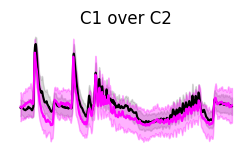

In [10]:
fig, axs = plt.subplots(1,1,figsize=(3,1.5))

axs.plot(mean_c1, color="black")
axs.fill_between(np.arange(0, std_c1.shape[0]),
                 mean_c1 + std_c1,
                 mean_c1 - std_c1,
                 alpha=0.3,
                 color="gray")

axs.plot(mean_c2, color="magenta")
axs.fill_between(np.arange(0, std_c1.shape[0]),
                 mean_c2 + std_c2,
                 mean_c2 - std_c2,
                 alpha=0.3,
                 color="magenta")

axs.axis("off")
axs.set_title("C1 over C2")

In [11]:
cluster_ids = df["cluster_gchirp"].unique()
cluster_ids = cluster_ids[~np.isnan(cluster_ids)].astype(np.int32)
cluster_ids = np.sort(cluster_ids)

n_clusters = len(cluster_ids)
print(f"N clusters: {n_clusters}")
print(cluster_ids)

N clusters: 8
[0 1 2 3 4 5 6 7]


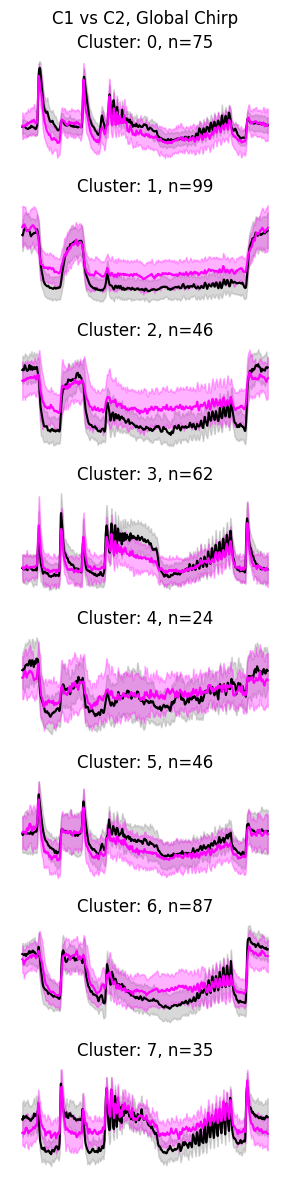

In [12]:
fig, axs = plt.subplots(n_clusters, 1, figsize=(3,1.5*n_clusters))
plt.suptitle("C1 vs C2, Global Chirp")

for cluster in cluster_ids:

    df_c1_cluster = df_c1_from_c2[df_c1_from_c2["cluster_gchirp"] == cluster]
    df_c2_cluster = df_c2_from_c2[df_c2_from_c2["cluster_gchirp"] == cluster]

    gchirp_averages_c1 = df_c1_cluster["average_norm_gChirp"]
    gchirp_averages_c2 = df_c2_cluster["average_norm_gChirp"]

    n_c1 = len(gchirp_averages_c1)
    n_c2 = len(gchirp_averages_c2)
    if n_c1 != n_c2:
        raise ValueError("Unequal number of ROIs in C1 vs C2")

    lengths = check_array_lengths(gchirp_averages_c1, gchirp_averages_c2)

    if lengths["unique_lengths"].shape != (1,):

        target_length = lengths["max_length"]
    
        gchirp_averages_c1 = gchirp_averages_c1.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
        gchirp_averages_c2 = gchirp_averages_c2.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
            
        #print(f"Padded arrays to: {target_length}")

    mean_c1 = np.mean(gchirp_averages_c1.values)
    std_c1 = np.std(gchirp_averages_c1.values)
    
    mean_c2 = np.mean(gchirp_averages_c2.values)
    std_c2 = np.std(gchirp_averages_c2.values)

    axs[cluster].plot(mean_c1, color="black")
    axs[cluster].fill_between(np.arange(0, std_c1.shape[0]),
                     mean_c1 + std_c1,
                     mean_c1 - std_c1,
                     alpha=0.3,
                     color="gray")
    
    axs[cluster].plot(mean_c2, color="magenta")
    axs[cluster].fill_between(np.arange(0, std_c1.shape[0]),
                     mean_c2 + std_c2,
                     mean_c2 - std_c2,
                     alpha=0.3,
                     color="magenta")
    
    axs[cluster].axis("off")
    axs[cluster].set_title(f"Cluster: {cluster}, n={n_c1}")

plt.tight_layout()
plt.savefig(f"../plots/responses/gchirp_C1vsC2_Filtered_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

## lChirp (with padding)

In [13]:
# Can start already from defined df's
print(df_c1_cluster_0.shape)
print(df_c2_cluster_0.shape)

(75, 48)
(75, 48)


In [14]:
lchirp_averages_c1 = df_c1_cluster_0["average_norm_lChirp"]
lchirp_averages_c2 = df_c2_cluster_0["average_norm_lChirp"]

print(lchirp_averages_c1.shape)
print(lchirp_averages_c2.shape)

(75,)
(75,)


In [15]:
lengths = check_array_lengths(lchirp_averages_c1, lchirp_averages_c2)
lengths

{'unique_lengths': array([16515, 16516]),
 'min_length': 16515,
 'max_length': 16516}

In [16]:
if lengths["unique_lengths"].shape != (1,):

    target_length = lengths["max_length"]

    lchirp_averages_c1 = lchirp_averages_c1.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
    lchirp_averages_c2 = lchirp_averages_c2.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
        
    print(f"Padded arrays to: {target_length}")

else:
    print("No padding require")

print(lchirp_averages_c1.shape)
print(lchirp_averages_c2.shape)

Padded arrays to: 16516
(75,)
(75,)


In [17]:
mean_c1 = np.mean(lchirp_averages_c1.values)
std_c1 = np.std(lchirp_averages_c1.values)

mean_c2 = np.mean(lchirp_averages_c2.values)
std_c2 = np.std(lchirp_averages_c2.values)

print("C1")
print(mean_c1.shape, std_c1.shape)

print("C2")
print(mean_c2.shape, std_c2.shape)

C1
(16516,) (16516,)
C2
(16516,) (16516,)


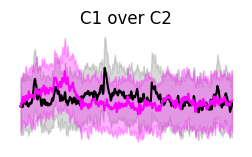

In [18]:
fig, axs = plt.subplots(1,1,figsize=(3,1.5))

axs.plot(mean_c1, color="black")
axs.fill_between(np.arange(0, std_c1.shape[0]),
                 mean_c1 + std_c1,
                 mean_c1 - std_c1,
                 alpha=0.3,
                 color="gray")

axs.plot(mean_c2, color="magenta")
axs.fill_between(np.arange(0, std_c1.shape[0]),
                 mean_c2 + std_c2,
                 mean_c2 - std_c2,
                 alpha=0.3,
                 color="magenta")

axs.axis("off")
axs.set_title("C1 over C2")

plt.show()

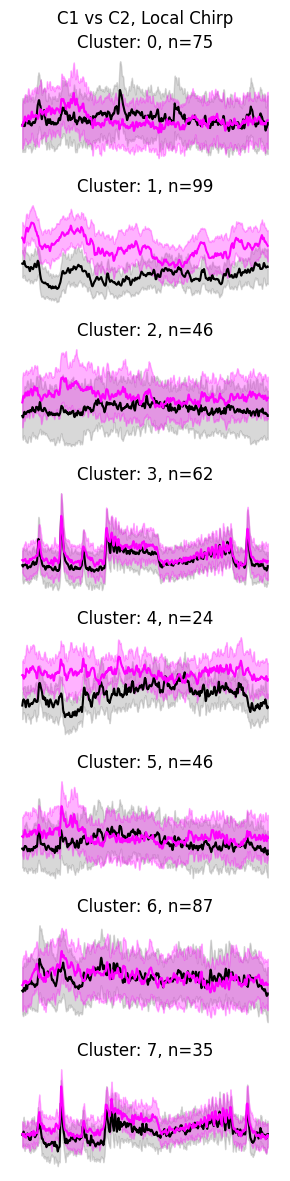

In [19]:
fig, axs = plt.subplots(n_clusters, 1, figsize=(3,1.5*n_clusters))
plt.suptitle("C1 vs C2, Local Chirp")

for cluster in cluster_ids:

    df_c1_cluster = df_c1_from_c2[df_c1_from_c2["cluster_gchirp"] == cluster]
    df_c2_cluster = df_c2_from_c2[df_c2_from_c2["cluster_gchirp"] == cluster]

    lchirp_averages_c1 = df_c1_cluster["average_norm_lChirp"]
    lchirp_averages_c2 = df_c2_cluster["average_norm_lChirp"]

    n_c1 = len(lchirp_averages_c1)
    n_c2 = len(lchirp_averages_c2)
    if n_c1 != n_c2:
        raise ValueError("Unequal number of ROIs in C1 vs C2")

    lengths = check_array_lengths(lchirp_averages_c1, lchirp_averages_c2)

    if lengths["unique_lengths"].shape != (1,):

        target_length = lengths["max_length"]
    
        lchirp_averages_c1 = lchirp_averages_c1.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
        lchirp_averages_c2 = lchirp_averages_c2.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
            
        #print(f"Padded arrays to: {target_length}")

    mean_c1 = np.mean(lchirp_averages_c1.values)
    std_c1 = np.std(lchirp_averages_c1.values)
    
    mean_c2 = np.mean(lchirp_averages_c2.values)
    std_c2 = np.std(lchirp_averages_c2.values)

    axs[cluster].plot(mean_c1, color="black")
    axs[cluster].fill_between(np.arange(0, std_c1.shape[0]),
                     mean_c1 + std_c1,
                     mean_c1 - std_c1,
                     alpha=0.3,
                     color="gray")
    
    axs[cluster].plot(mean_c2, color="magenta")
    axs[cluster].fill_between(np.arange(0, std_c1.shape[0]),
                     mean_c2 + std_c2,
                     mean_c2 - std_c2,
                     alpha=0.3,
                     color="magenta")
    
    axs[cluster].axis("off")
    axs[cluster].set_title(f"Cluster: {cluster}, n={n_c1}")

plt.tight_layout()
plt.savefig(f"../plots/responses/lchirp_C1vsC2_StrictlyFiltered_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

## Moving bar

In [20]:
# Can start already from defined df's
print(df_c1_cluster_0.shape)
print(df_c2_cluster_0.shape)

(75, 48)
(75, 48)


In [21]:
mb_averages_c1 = df_c1_cluster_0["average_norm_movingbar"]
mb_averages_c2 = df_c2_cluster_0["average_norm_movingbar"]

print(mb_averages_c1.shape)
print(mb_averages_c2.shape)

(75,)
(75,)


In [22]:
lengths = check_array_lengths(mb_averages_c1, mb_averages_c2)
lengths

{'unique_lengths': array([2028]), 'min_length': 2028, 'max_length': 2028}

In [23]:
if lengths["unique_lengths"].shape != (1,):

    target_length = lengths["max_length"]

    mb_averages_c1 = mb_averages_c1.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
    mb_averages_c2 = mb_averages_c2.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
        
    print(f"Padded arrays to: {target_length}")

else:
    print("No padding required")

print(mb_averages_c1.shape)
print(mb_averages_c2.shape)

No padding required
(75,)
(75,)


In [24]:
mean_c1 = np.mean(mb_averages_c1.values)
std_c1 = np.std(mb_averages_c1.values)

mean_c2 = np.mean(mb_averages_c2.values)
std_c2 = np.std(mb_averages_c2.values)

print("C1")
print(mean_c1.shape, std_c1.shape)

print("C2")
print(mean_c2.shape, std_c2.shape)

C1
(2028,) (2028,)
C2
(2028,) (2028,)


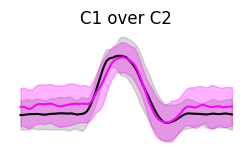

In [25]:
fig, axs = plt.subplots(1,1,figsize=(3,1.5))

axs.plot(mean_c1, color="black")
axs.fill_between(np.arange(0, std_c1.shape[0]),
                 mean_c1 + std_c1,
                 mean_c1 - std_c1,
                 alpha=0.3,
                 color="gray")

axs.plot(mean_c2, color="magenta")
axs.fill_between(np.arange(0, std_c1.shape[0]),
                 mean_c2 + std_c2,
                 mean_c2 - std_c2,
                 alpha=0.3,
                 color="magenta")

axs.axis("off")
axs.set_title("C1 over C2")

plt.show()

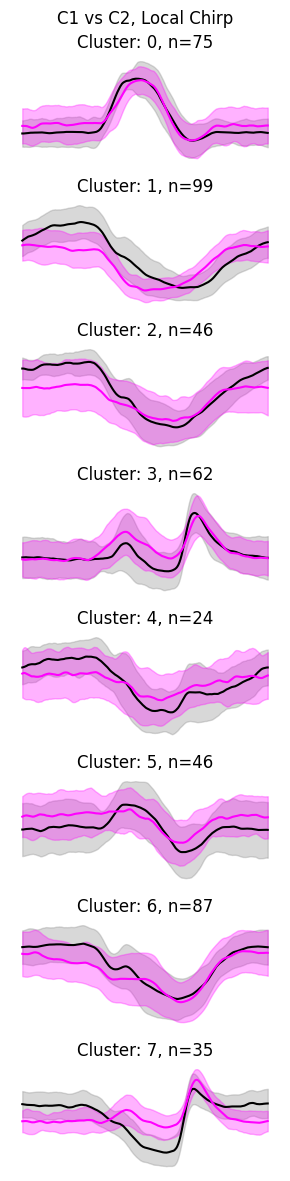

In [26]:
fig, axs = plt.subplots(n_clusters, 1, figsize=(3,1.5*n_clusters))
plt.suptitle("C1 vs C2, Local Chirp")

for cluster in cluster_ids:

    df_c1_cluster = df_c1_from_c2[df_c1_from_c2["cluster_gchirp"] == cluster]
    df_c2_cluster = df_c2_from_c2[df_c2_from_c2["cluster_gchirp"] == cluster]

    mb_averages_c1 = df_c1_cluster["average_norm_movingbar"]
    mb_averages_c2 = df_c2_cluster["average_norm_movingbar"]

    n_c1 = len(mb_averages_c1)
    n_c2 = len(mb_averages_c2)
    if n_c1 != n_c2:
        raise ValueError("Unequal number of ROIs in C1 vs C2")

    lengths = check_array_lengths(mb_averages_c1, mb_averages_c2)

    if lengths["unique_lengths"].shape != 1:

        target_length = lengths["max_length"]
    
        mb_averages_c1 = mb_averages_c1.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
        mb_averages_c2 = mb_averages_c2.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
            
        #print(f"Padded arrays to: {target_length}")

    mean_c1 = np.mean(mb_averages_c1.values)
    std_c1 = np.std(mb_averages_c1.values)
    
    mean_c2 = np.mean(mb_averages_c2.values)
    std_c2 = np.std(mb_averages_c2.values)

    axs[cluster].plot(mean_c1, color="black")
    axs[cluster].fill_between(np.arange(0, std_c1.shape[0]),
                     mean_c1 + std_c1,
                     mean_c1 - std_c1,
                     alpha=0.3,
                     color="gray")
    
    axs[cluster].plot(mean_c2, color="magenta")
    axs[cluster].fill_between(np.arange(0, std_c1.shape[0]),
                     mean_c2 + std_c2,
                     mean_c2 - std_c2,
                     alpha=0.3,
                     color="magenta")
    
    axs[cluster].axis("off")
    axs[cluster].set_title(f"Cluster: {cluster}, n={n_c1}")

plt.tight_layout()
plt.savefig(f"../plots/responses/mb_C1vsC2_StrictlyFiltered_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

# C1 / DETA/NO

## gChirp

In [27]:
df_detano.shape

(1158, 48)

In [28]:
df_c1_from_no = df_detano[df_detano["cond2"] == "C1"]
df_no_from_no = df_detano[df_detano["cond2"] == "DETANO"]

print(df_c1_from_no.shape)
print(df_no_from_no.shape)

(579, 48)
(579, 48)


In [29]:
df_c1_cluster_0 = df_c1_from_no[df_c1_from_no["cluster_gchirp"] == 0]
df_no_cluster_0 = df_no_from_no[df_no_from_no["cluster_gchirp"] == 0]

print(df_c1_cluster_0.shape)
print(df_no_cluster_0.shape)

(73, 48)
(73, 48)


In [30]:
gchirp_averages_c1 = df_c1_cluster_0["average_norm_gChirp"]
gchirp_averages_no = df_no_cluster_0["average_norm_gChirp"]

print(gchirp_averages_c1.shape)
print(gchirp_averages_no.shape)

(73,)
(73,)


In [31]:
lengths = check_array_lengths(gchirp_averages_c1, gchirp_averages_no)
lengths

{'unique_lengths': array([16515, 16516]),
 'min_length': 16515,
 'max_length': 16516}

In [32]:
if lengths["unique_lengths"].shape != (1,):

    target_length = lengths["max_length"]

    gchirp_averages_c1 = gchirp_averages_c1.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
    gchirp_averages_no = gchirp_averages_no.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
        
    print(f"Padded arrays to: {target_length}")

else:
    print("No padding required")

print(gchirp_averages_c1.shape)
print(gchirp_averages_no.shape)

Padded arrays to: 16516
(73,)
(73,)


In [33]:
mean_c1 = np.mean(gchirp_averages_c1.values)
std_c1 = np.std(gchirp_averages_c1.values)

mean_no = np.mean(gchirp_averages_no.values)
std_no = np.std(gchirp_averages_no.values)

print("C1")
print(mean_c1.shape, std_c1.shape)

print("NO")
print(mean_no.shape, std_no.shape)

C1
(16516,) (16516,)
NO
(16516,) (16516,)


Text(0.5, 1.0, 'C1 over DETA/NO')

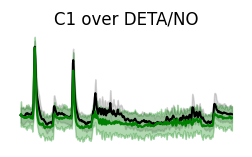

In [34]:
fig, axs = plt.subplots(1,1,figsize=(3,1.5))

axs.plot(mean_c1, color="black")
axs.fill_between(np.arange(0, std_c1.shape[0]),
                 mean_c1 + std_c1,
                 mean_c1 - std_c1,
                 alpha=0.3,
                 color="gray")

axs.plot(mean_no, color="green")
axs.fill_between(np.arange(0, std_no.shape[0]),
                 mean_no + std_no,
                 mean_no - std_no,
                 alpha=0.3,
                 color="green")

axs.axis("off")
axs.set_title("C1 over DETA/NO")

In [35]:
cluster_ids = df_detano["cluster_gchirp"].unique()
cluster_ids = cluster_ids[~np.isnan(cluster_ids)].astype(np.int32)
cluster_ids = np.sort(cluster_ids)

n_clusters = len(cluster_ids)
print(f"N clusters: {n_clusters}")
print(cluster_ids)

N clusters: 7
[0 2 3 4 5 6 7]


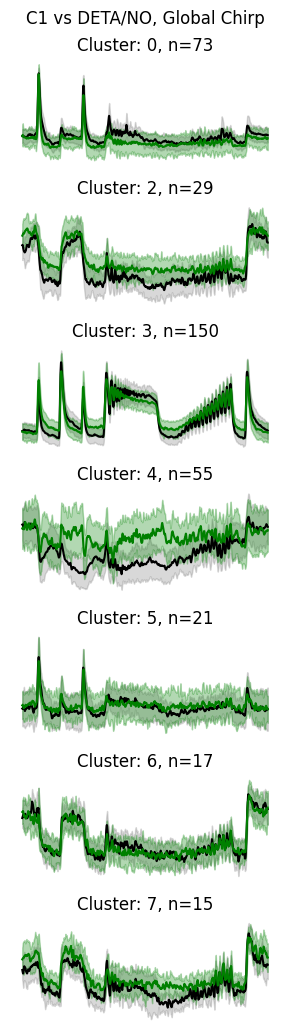

In [37]:
fig, axs = plt.subplots(n_clusters, 1, figsize=(3,1.5*n_clusters))
plt.suptitle("C1 vs DETA/NO, Global Chirp")

for i, cluster in enumerate(cluster_ids):

    df_c1_cluster = df_c1_from_no[df_c1_from_no["cluster_gchirp"] == cluster]
    df_no_cluster = df_no_from_no[df_no_from_no["cluster_gchirp"] == cluster]

    gchirp_averages_c1 = df_c1_cluster["average_norm_gChirp"]
    gchirp_averages_no = df_no_cluster["average_norm_gChirp"]

    n_c1 = len(gchirp_averages_c1)
    n_no = len(gchirp_averages_no)
    if n_c1 != n_no:
        raise ValueError("Unequal number of ROIs in C1 vs NO")

    lengths = check_array_lengths(gchirp_averages_c1, gchirp_averages_no)

    if lengths["unique_lengths"].shape != (1,):

        target_length = lengths["max_length"]
    
        gchirp_averages_c1 = gchirp_averages_c1.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
        gchirp_averages_no = gchirp_averages_no.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
            
        #print(f"Padded arrays to: {target_length}")

    # If else statement to check how many traces are in each cluster
    if gchirp_averages_c1.shape > (1,):
        mean_c1 = np.mean(gchirp_averages_c1.values)
        std_c1 = np.std(gchirp_averages_c1.values)
        
        mean_no = np.mean(gchirp_averages_no.values)
        std_no = np.std(gchirp_averages_no.values)
    
        axs[i].plot(mean_c1, color="black")
        axs[i].fill_between(np.arange(0, std_c1.shape[0]),
                         mean_c1 + std_c1,
                         mean_c1 - std_c1,
                         alpha=0.3,
                         color="gray")
        
        axs[i].plot(mean_no, color="green")
        axs[i].fill_between(np.arange(0, std_no.shape[0]),
                         mean_no + std_no,
                         mean_no - std_no,
                         alpha=0.3,
                         color="green")

    else:
        trace_c1 = gchirp_averages_c1.values[0]
        trace_no = gchirp_averages_no.values[0]
    
        axs[i].plot(trace_c1, color="black")
        axs[i].plot(trace_no, color="green")
    
    axs[i].axis("off")
    axs[i].set_title(f"Cluster: {cluster}, n={n_c1}")

plt.tight_layout()
plt.savefig(f"../plots/responses/gchirp_C1vsNO_StrictlyFiltered_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

## lChirp

In [38]:
lchirp_averages_c1 = df_c1_cluster_0["average_norm_lChirp"]
lchirp_averages_no = df_no_cluster_0["average_norm_lChirp"]

print(lchirp_averages_c1.shape)
print(lchirp_averages_no.shape)

(73,)
(73,)


In [39]:
lengths = check_array_lengths(lchirp_averages_c1, lchirp_averages_no)
lengths

{'unique_lengths': array([16504, 16507, 16516]),
 'min_length': 16504,
 'max_length': 16516}

In [40]:
if lengths["unique_lengths"].shape != (1,):

    target_length = lengths["max_length"]

    lchirp_averages_c1 = lchirp_averages_c1.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
    lchirp_averages_no = lchirp_averages_no.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
        
    print(f"Padded arrays to: {target_length}")

else:
    print("No padding required")

print(lchirp_averages_c1.shape)
print(lchirp_averages_no.shape)

Padded arrays to: 16516
(73,)
(73,)


In [41]:
mean_c1 = np.mean(lchirp_averages_c1.values)
std_c1 = np.std(lchirp_averages_c1.values)

mean_no = np.mean(lchirp_averages_no.values)
std_no = np.std(lchirp_averages_no.values)

print("C1")
print(mean_c1.shape, std_c1.shape)

print("NO")
print(mean_no.shape, std_no.shape)

C1
(16516,) (16516,)
NO
(16516,) (16516,)


Text(0.5, 1.0, 'C1 over DETA/NO')

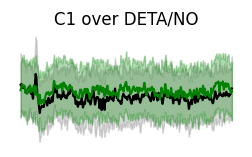

In [42]:
fig, axs = plt.subplots(1,1,figsize=(3,1.5))

axs.plot(mean_c1, color="black")
axs.fill_between(np.arange(0, std_c1.shape[0]),
                 mean_c1 + std_c1,
                 mean_c1 - std_c1,
                 alpha=0.3,
                 color="gray")

axs.plot(mean_no, color="green")
axs.fill_between(np.arange(0, std_no.shape[0]),
                 mean_no + std_no,
                 mean_no - std_no,
                 alpha=0.3,
                 color="green")

axs.axis("off")
axs.set_title("C1 over DETA/NO")

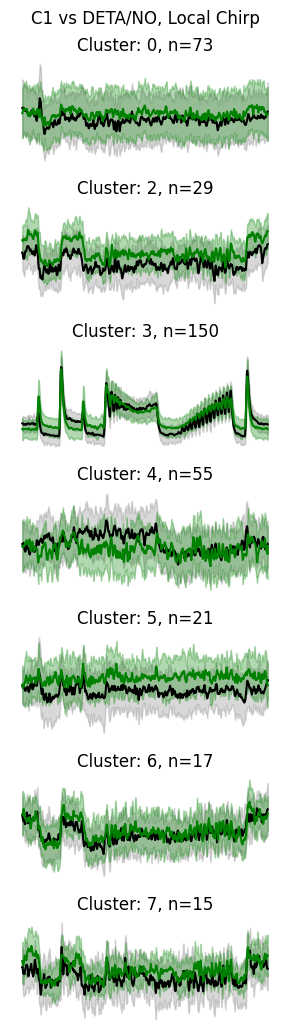

In [43]:
fig, axs = plt.subplots(n_clusters, 1, figsize=(3,1.5*n_clusters))
plt.suptitle("C1 vs DETA/NO, Local Chirp")

for i, cluster in enumerate(cluster_ids):

    df_c1_cluster = df_c1_from_no[df_c1_from_no["cluster_gchirp"] == cluster]
    df_no_cluster = df_no_from_no[df_no_from_no["cluster_gchirp"] == cluster]

    lchirp_averages_c1 = df_c1_cluster["average_norm_lChirp"]
    lchirp_averages_no = df_no_cluster["average_norm_lChirp"]

    n_c1 = len(lchirp_averages_c1)
    n_no = len(lchirp_averages_no)
    if n_c1 != n_no:
        raise ValueError("Unequal number of ROIs in C1 vs NO")

    lengths = check_array_lengths(lchirp_averages_c1, lchirp_averages_no)

    if lengths["unique_lengths"].shape != (1,):

        target_length = lengths["max_length"]
    
        lchirp_averages_c1 = lchirp_averages_c1.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
        lchirp_averages_no = lchirp_averages_no.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
            
        #print(f"Padded arrays to: {target_length}")

    # If else statement to check how many traces are in each cluster
    if lchirp_averages_c1.shape > (1,):
        mean_c1 = np.mean(lchirp_averages_c1.values)
        std_c1 = np.std(lchirp_averages_c1.values)
        
        mean_no = np.mean(lchirp_averages_no.values)
        std_no = np.std(lchirp_averages_no.values)
    
        axs[i].plot(mean_c1, color="black")
        axs[i].fill_between(np.arange(0, std_c1.shape[0]),
                         mean_c1 + std_c1,
                         mean_c1 - std_c1,
                         alpha=0.3,
                         color="gray")
        
        axs[i].plot(mean_no, color="green")
        axs[i].fill_between(np.arange(0, std_no.shape[0]),
                         mean_no + std_no,
                         mean_no - std_no,
                         alpha=0.3,
                         color="green")

    else:
        trace_c1 = lchirp_averages_c1.values[0]
        trace_no = lchirp_averages_no.values[0]
    
        axs[i].plot(trace_c1, color="black")
        axs[i].plot(trace_no, color="green")
    
    axs[i].axis("off")
    axs[i].set_title(f"Cluster: {cluster}, n={n_c1}")

plt.tight_layout()
plt.savefig(f"../plots/responses/lchirp_C1vsNO_StrictlyFiltered_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

## Moving bar

## lChirp

In [44]:
mb_averages_c1 = df_c1_cluster_0["average_norm_movingbar"]
mb_averages_no = df_no_cluster_0["average_norm_movingbar"]

print(mb_averages_c1.shape)
print(mb_averages_no.shape)

(73,)
(73,)


In [45]:
lengths = check_array_lengths(mb_averages_c1, mb_averages_no)
lengths

{'unique_lengths': array([2028]), 'min_length': 2028, 'max_length': 2028}

In [46]:
if lengths["unique_lengths"].shape != (1,):

    target_length = lengths["max_length"]

    mb_averages_c1 = mb_averages_c1.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
    mb_averages_no = mb_averages_no.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
        
    print(f"Padded arrays to: {target_length}")

else:
    print("No padding required")

print(mb_averages_c1.shape)
print(mb_averages_no.shape)

No padding required
(73,)
(73,)


In [47]:
mean_c1 = np.mean(mb_averages_c1.values)
std_c1 = np.std(mb_averages_c1.values)

mean_no = np.mean(mb_averages_no.values)
std_no = np.std(mb_averages_no.values)

print("C1")
print(mean_c1.shape, std_c1.shape)

print("NO")
print(mean_no.shape, std_no.shape)

C1
(2028,) (2028,)
NO
(2028,) (2028,)


Text(0.5, 1.0, 'C1 over DETA/NO')

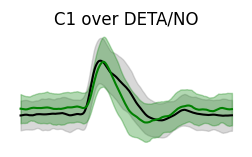

In [48]:
fig, axs = plt.subplots(1,1,figsize=(3,1.5))

axs.plot(mean_c1, color="black")
axs.fill_between(np.arange(0, std_c1.shape[0]),
                 mean_c1 + std_c1,
                 mean_c1 - std_c1,
                 alpha=0.3,
                 color="gray")

axs.plot(mean_no, color="green")
axs.fill_between(np.arange(0, std_no.shape[0]),
                 mean_no + std_no,
                 mean_no - std_no,
                 alpha=0.3,
                 color="green")

axs.axis("off")
axs.set_title("C1 over DETA/NO")

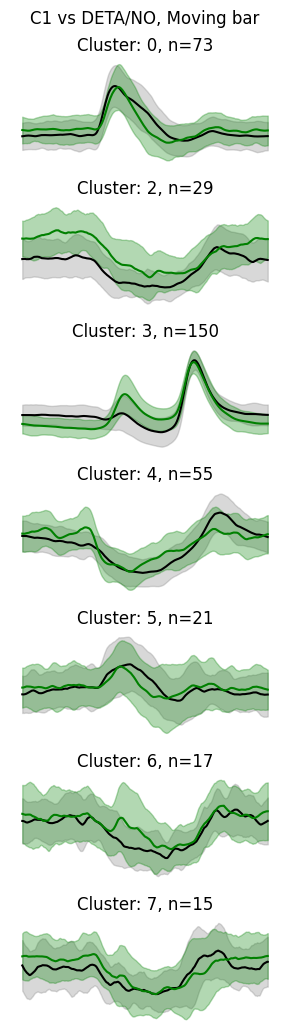

In [49]:
fig, axs = plt.subplots(n_clusters, 1, figsize=(3,1.5*n_clusters))
plt.suptitle("C1 vs DETA/NO, Moving bar")

for i, cluster in enumerate(cluster_ids):

    df_c1_cluster = df_c1_from_no[df_c1_from_no["cluster_gchirp"] == cluster]
    df_no_cluster = df_no_from_no[df_no_from_no["cluster_gchirp"] == cluster]

    mb_averages_c1 = df_c1_cluster["average_norm_movingbar"]
    mb_averages_no = df_no_cluster["average_norm_movingbar"]

    n_c1 = len(mb_averages_c1)
    n_no = len(mb_averages_no)
    if n_c1 != n_no:
        raise ValueError("Unequal number of ROIs in C1 vs NO")

    lengths = check_array_lengths(mb_averages_c1, mb_averages_no)

    if lengths["unique_lengths"].shape != (1,):

        target_length = lengths["max_length"]
    
        mb_averages_c1 = mb_averages_c1.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
        mb_averages_no = mb_averages_no.apply(lambda arr: pad_to_length(arr, target_length, pad_value="mean"))
            
        #print(f"Padded arrays to: {target_length}")

    # If else statement to check how many traces are in each cluster
    if mb_averages_c1.shape > (1,):
        mean_c1 = np.mean(mb_averages_c1.values)
        std_c1 = np.std(mb_averages_c1.values)
        
        mean_no = np.mean(mb_averages_no.values)
        std_no = np.std(mb_averages_no.values)
    
        axs[i].plot(mean_c1, color="black")
        axs[i].fill_between(np.arange(0, std_c1.shape[0]),
                         mean_c1 + std_c1,
                         mean_c1 - std_c1,
                         alpha=0.3,
                         color="gray")
        
        axs[i].plot(mean_no, color="green")
        axs[i].fill_between(np.arange(0, std_no.shape[0]),
                         mean_no + std_no,
                         mean_no - std_no,
                         alpha=0.3,
                         color="green")

    else:
        trace_c1 = mb_averages_c1.values[0]
        trace_no = mb_averages_no.values[0]
    
        axs[i].plot(trace_c1, color="black")
        axs[i].plot(trace_no, color="green")
    
    axs[i].axis("off")
    axs[i].set_title(f"Cluster: {cluster}, n={n_c1}")

plt.tight_layout()
plt.savefig(f"../plots/responses/mb_C1vsNO_StrictlyFiltered_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()